**ANOMALY DETECTION OC-SVM**

In [3]:
import digitalhub as dh
import zipfile
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [48]:
flood = 0
jobs = [
    ("cos",   f"net_v3_{flood}per"),
    ("ocsvm", f"net_v3_{flood}per"),
    ("pca",   f"net_v3_{flood}per_k9"),
    ("md",    f"net_v3_{flood}per"),
    ("ocsvm", f"net_v3_{flood}per_w"),
]

def load_job(metodo, job_name):
    results_dir = f"/tmp/anomaly_results_{metodo}_{job_name}"      
    shutil.rmtree(results_dir, ignore_errors=True)
    zip_path = project.get_artifact(f"anomaly_results_{metodo}_{job_name}").download(f"{results_dir}.zip", overwrite=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(results_dir)
    with open(f"{results_dir}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{results_dir}/scores.csv")
    return results, df

summary = []
all_rules = {}

for metodo, job_name in jobs:
    results, df = load_job(metodo, job_name)
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    summary.append({
        "metodo": metodo,
        "job_name": job_name,
        "min_flood_area": results.get("min_flood_area"),
        "n_fit": results.get("n_fit"), "n_normali": results.get("n_normali"), "n_anomale": results.get("n_anomale"),
        "score_normali": f"{score_normal.mean():.2f} ± {score_normal.std():.2f}",
        "score_anomale": f"{score_anom.mean():.2f} ± {score_anom.std():.2f}",
        "auroc": results.get("auroc", results.get("auroc_cos_sim_low_anom")),   
    })
    all_rules[(metodo, job_name)] = pd.DataFrame(results["rules"]).T

df_summary = pd.DataFrame(summary).set_index(["metodo", "job_name"])
df_rules = pd.concat(all_rules, names=["metodo", "job_name", "regola"])

df_summary

,,min_flood_area,n_fit,n_normali,n_anomale,score_normali,score_anomale,auroc
metodo,job_name,,,,,,,
cos,net_v3_0per,0.0,2572,2402,2402,0.36 ± 0.13,0.34 ± 0.15,0.537590
ocsvm,net_v3_0per,0.0,2572,2402,2402,1.54 ± 1.10,0.92 ± 1.00,0.658010
pca,net_v3_0per_k9,0.0,2572,2402,2402,-177.14 ± 40.19,-207.22 ± 40.25,0.703005
md,net_v3_0per,0.0,2572,2402,2402,-291.68 ± 330.46,-388.52 ± 2203.51,0.710829
ocsvm,net_v3_0per_w,0.0,2572,2402,2402,1.79 ± 1.72,0.49 ± 1.77,0.712104


In [49]:
df_rules

soglia      TP     FP  \
metodo job_name       regola                                                   
cos    net_v3_0per    cos_sim > m+1*std              0.491210   367.0  367.0   
                      cos_sim < m-1*std              0.229413   571.0  373.0   
                      cos_sim fuori da m+-1*std           NaN   938.0  740.0   
ocsvm  net_v3_0per    ocsvm score < 0                0.000000   453.0  212.0   
pca    net_v3_0per_k9 pca score < soglia (FA 5%)  -242.643402   454.0   72.0   
                      pca score < soglia (FA 10%) -228.746674   715.0  146.0   
                      pca score < soglia (FA 15%) -219.643829   910.0  190.0   
                      pca score < soglia (FA 20%) -211.264069  1108.0  249.0   
                      pca score < soglia (FA 25%) -203.317673  1302.0  317.0   
                      pca score < soglia (FA 30%) -196.502960  1462.0  383.0   
md     net_v3_0per    md score < soglia (FA 5%)   -423.080209   387.0   62.0   
                      md score < soglia (FA 10%)  -372.668424   676.0  104.0   
                      md score < soglia (FA 15%)  -338.706003   945.0  183.0   
                      md score < soglia (FA 20%)  -320.930848  1134.0  234.0   
                      md score < soglia (FA 25%)  -305.564461  1294.0  286.0   
                      md score < soglia (FA 30%)  -290.812020  1473.0  359.0   
ocsvm  net_v3_0per_w  ocsvm score < 0                0.000000   879.0  323.0   

                                                       FN      TN   FA_rate  \
metodo job_name       regola                                                  
cos    net_v3_0per    cos_sim > m+1*std            2035.0  2035.0  0.152789   
                      cos_sim < m-1*std            1831.0  2029.0  0.155287   
                      cos_sim fuori da m+-1*std    1464.0  1662.0  0.308077   
ocsvm  net_v3_0per    ocsvm score < 0              1949.0  2190.0  0.088260   
pca    net_v3_0per_k9 pca score < soglia (FA 5%)   1948.0  1129.0  0.059950   
                      pca score < soglia (FA 10%)  1687.0  1055.0  0.121565   
                      pca score < soglia (FA 15%)  1492.0  1011.0  0.158201   
                      pca score < soglia (FA 20%)  1294.0   952.0  0.207327   
                      pca score < soglia (FA 25%)  1100.0   884.0  0.263947   
                      pca score < soglia (FA 30%)   940.0   818.0  0.318901   
md     net_v3_0per    md score < soglia (FA 5%)    2015.0  1139.0  0.051624   
                      md score < soglia (FA 10%)   1726.0  1097.0  0.086595   
                      md score < soglia (FA 15%)   1457.0  1018.0  0.152373   
                      md score < soglia (FA 20%)   1268.0   967.0  0.194838   
                      md score < soglia (FA 25%)   1108.0   915.0  0.238135   
                      md score < soglia (FA 30%)    929.0   842.0  0.298918   
ocsvm  net_v3_0per_w  ocsvm score < 0              1523.0  2079.0  0.134471   

                                                    MA_rate       REC  \
metodo job_name       regola                                            
cos    net_v3_0per    cos_sim > m+1*std            0.847211  0.152789   
                      cos_sim < m-1*std            0.762281  0.237719   
                      cos_sim fuori da m+-1*std    0.609492  0.390508   
ocsvm  net_v3_0per    ocsvm score < 0              0.811407  0.188593   
pca    net_v3_0per_k9 pca score < soglia (FA 5%)   0.810991  0.189009   
                      pca score < soglia (FA 10%)  0.702331  0.297669   
                      pca score < soglia (FA 15%)  0.621149  0.378851   
                      pca score < soglia (FA 20%)  0.538718  0.461282   
                      pca score < soglia (FA 25%)  0.457952  0.542048   
                      pca score < soglia (FA 30%)  0.391341  0.608659   
md     net_v3_0per    md score < soglia (FA 5%)    0.838884  0.161116   
                      md score < soglia (FA 10%)   0.718568  0.281432   
          

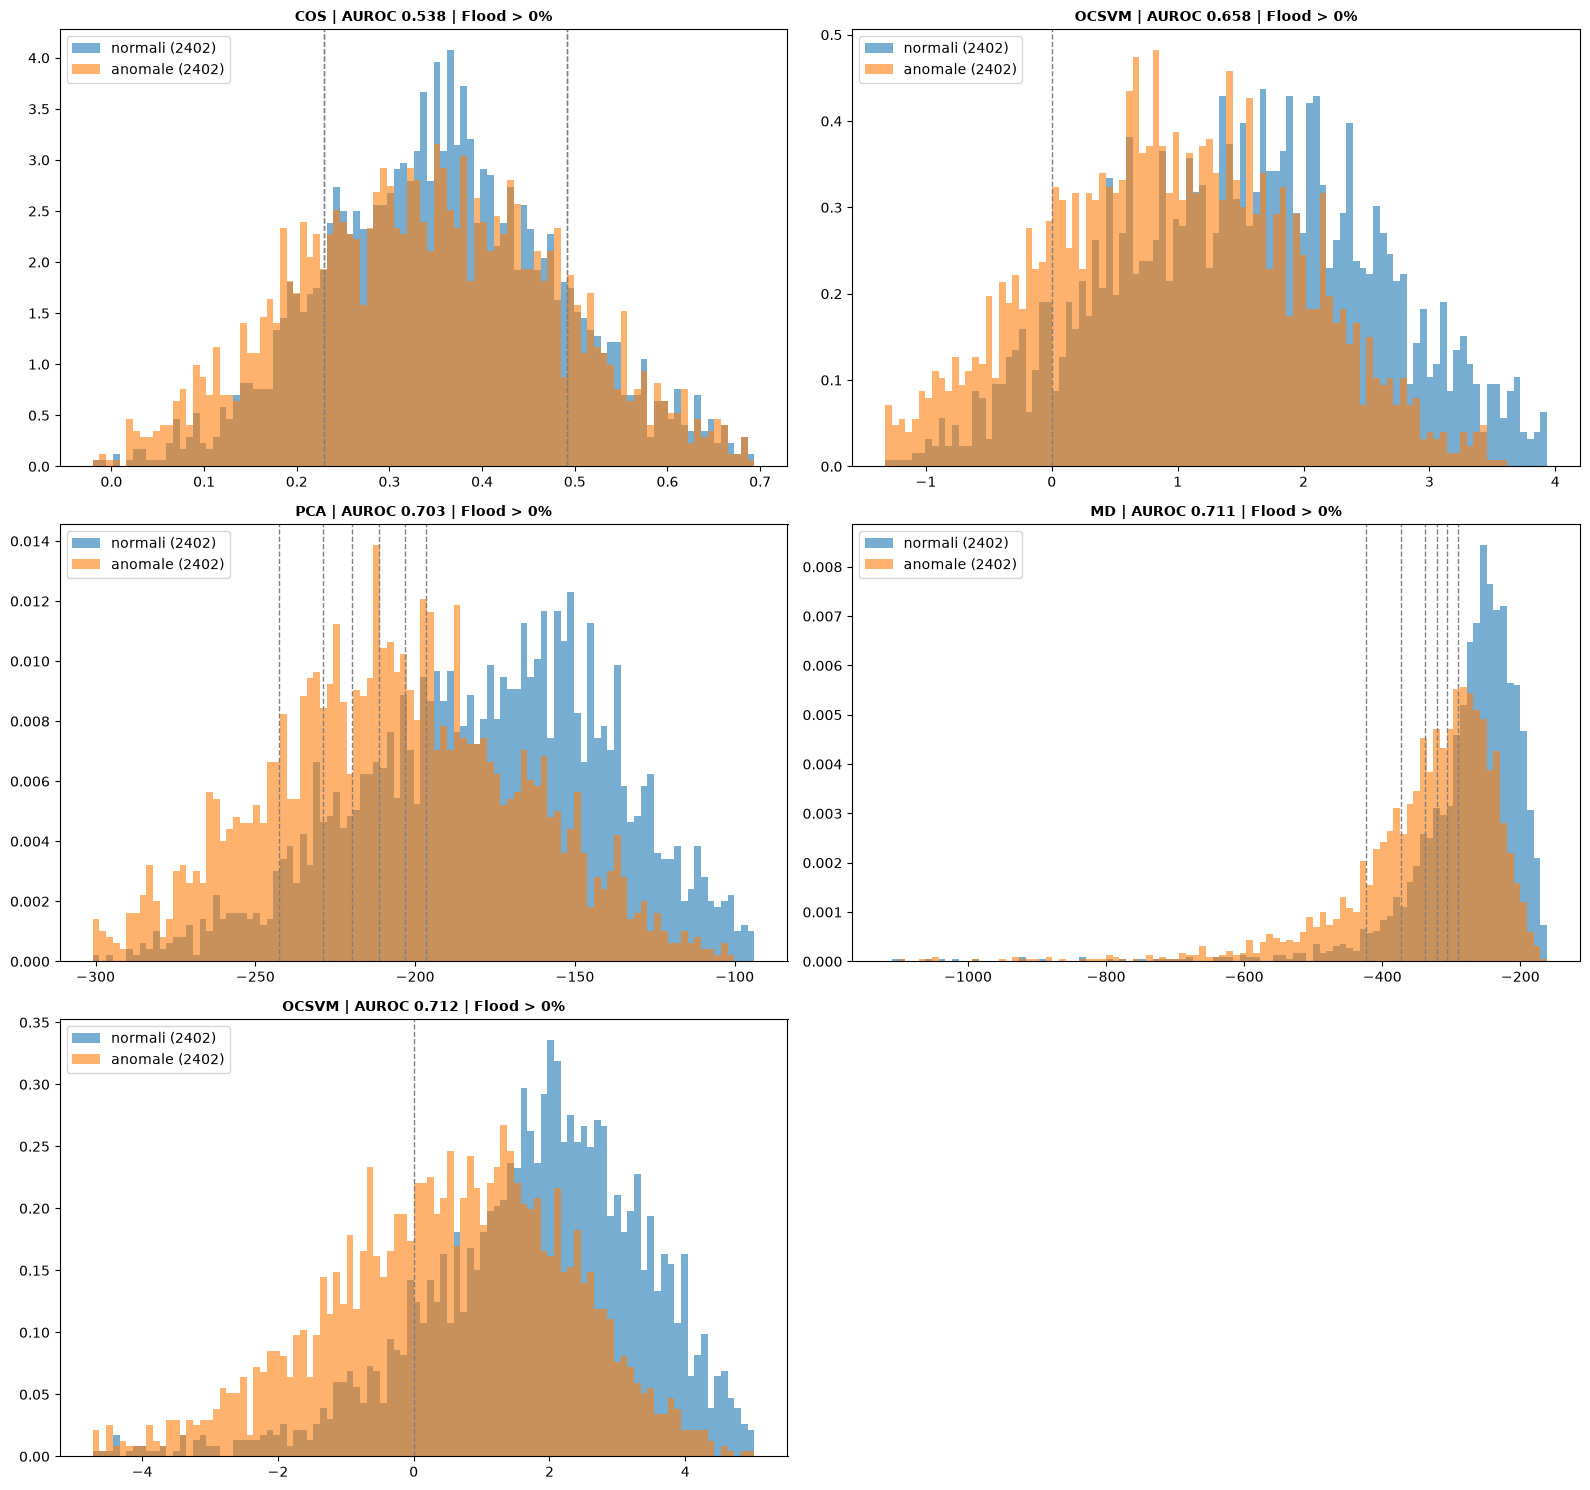

In [50]:
def plot_hist(ax, metodo, job_name, results, df):
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        etichetta = nome.split("(")[-1].rstrip(")")
        for chiave in ("soglia", "soglia_low", "soglia_high"):
            s = r.get(chiave)
            if s is not None and lo <= s <= hi:
                ax.axvline(x=s, color="gray", linestyle="--", linewidth=1)
                ax.text(s, ax.get_ylim()[1] * 0.97, "", rotation=90, va="top", ha="right", fontsize=8)

    auroc = results.get("auroc", results.get("auroc_cos_sim_low_anom"))
    ax.legend(loc="upper left")
    ax.set_title(f"{metodo.upper()} | AUROC {auroc:.3f} | Flood > {flood}%", fontsize=10, fontweight="bold")


n_cols = 2
n_rows = int(np.ceil(len(jobs) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 5 * n_rows), squeeze=False)

for ax, (metodo, job_name) in zip(axes.flat, jobs):
    results, df = load_job(metodo, job_name)
    plot_hist(ax, metodo, job_name, results, df)

for ax in axes.flat[len(jobs):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

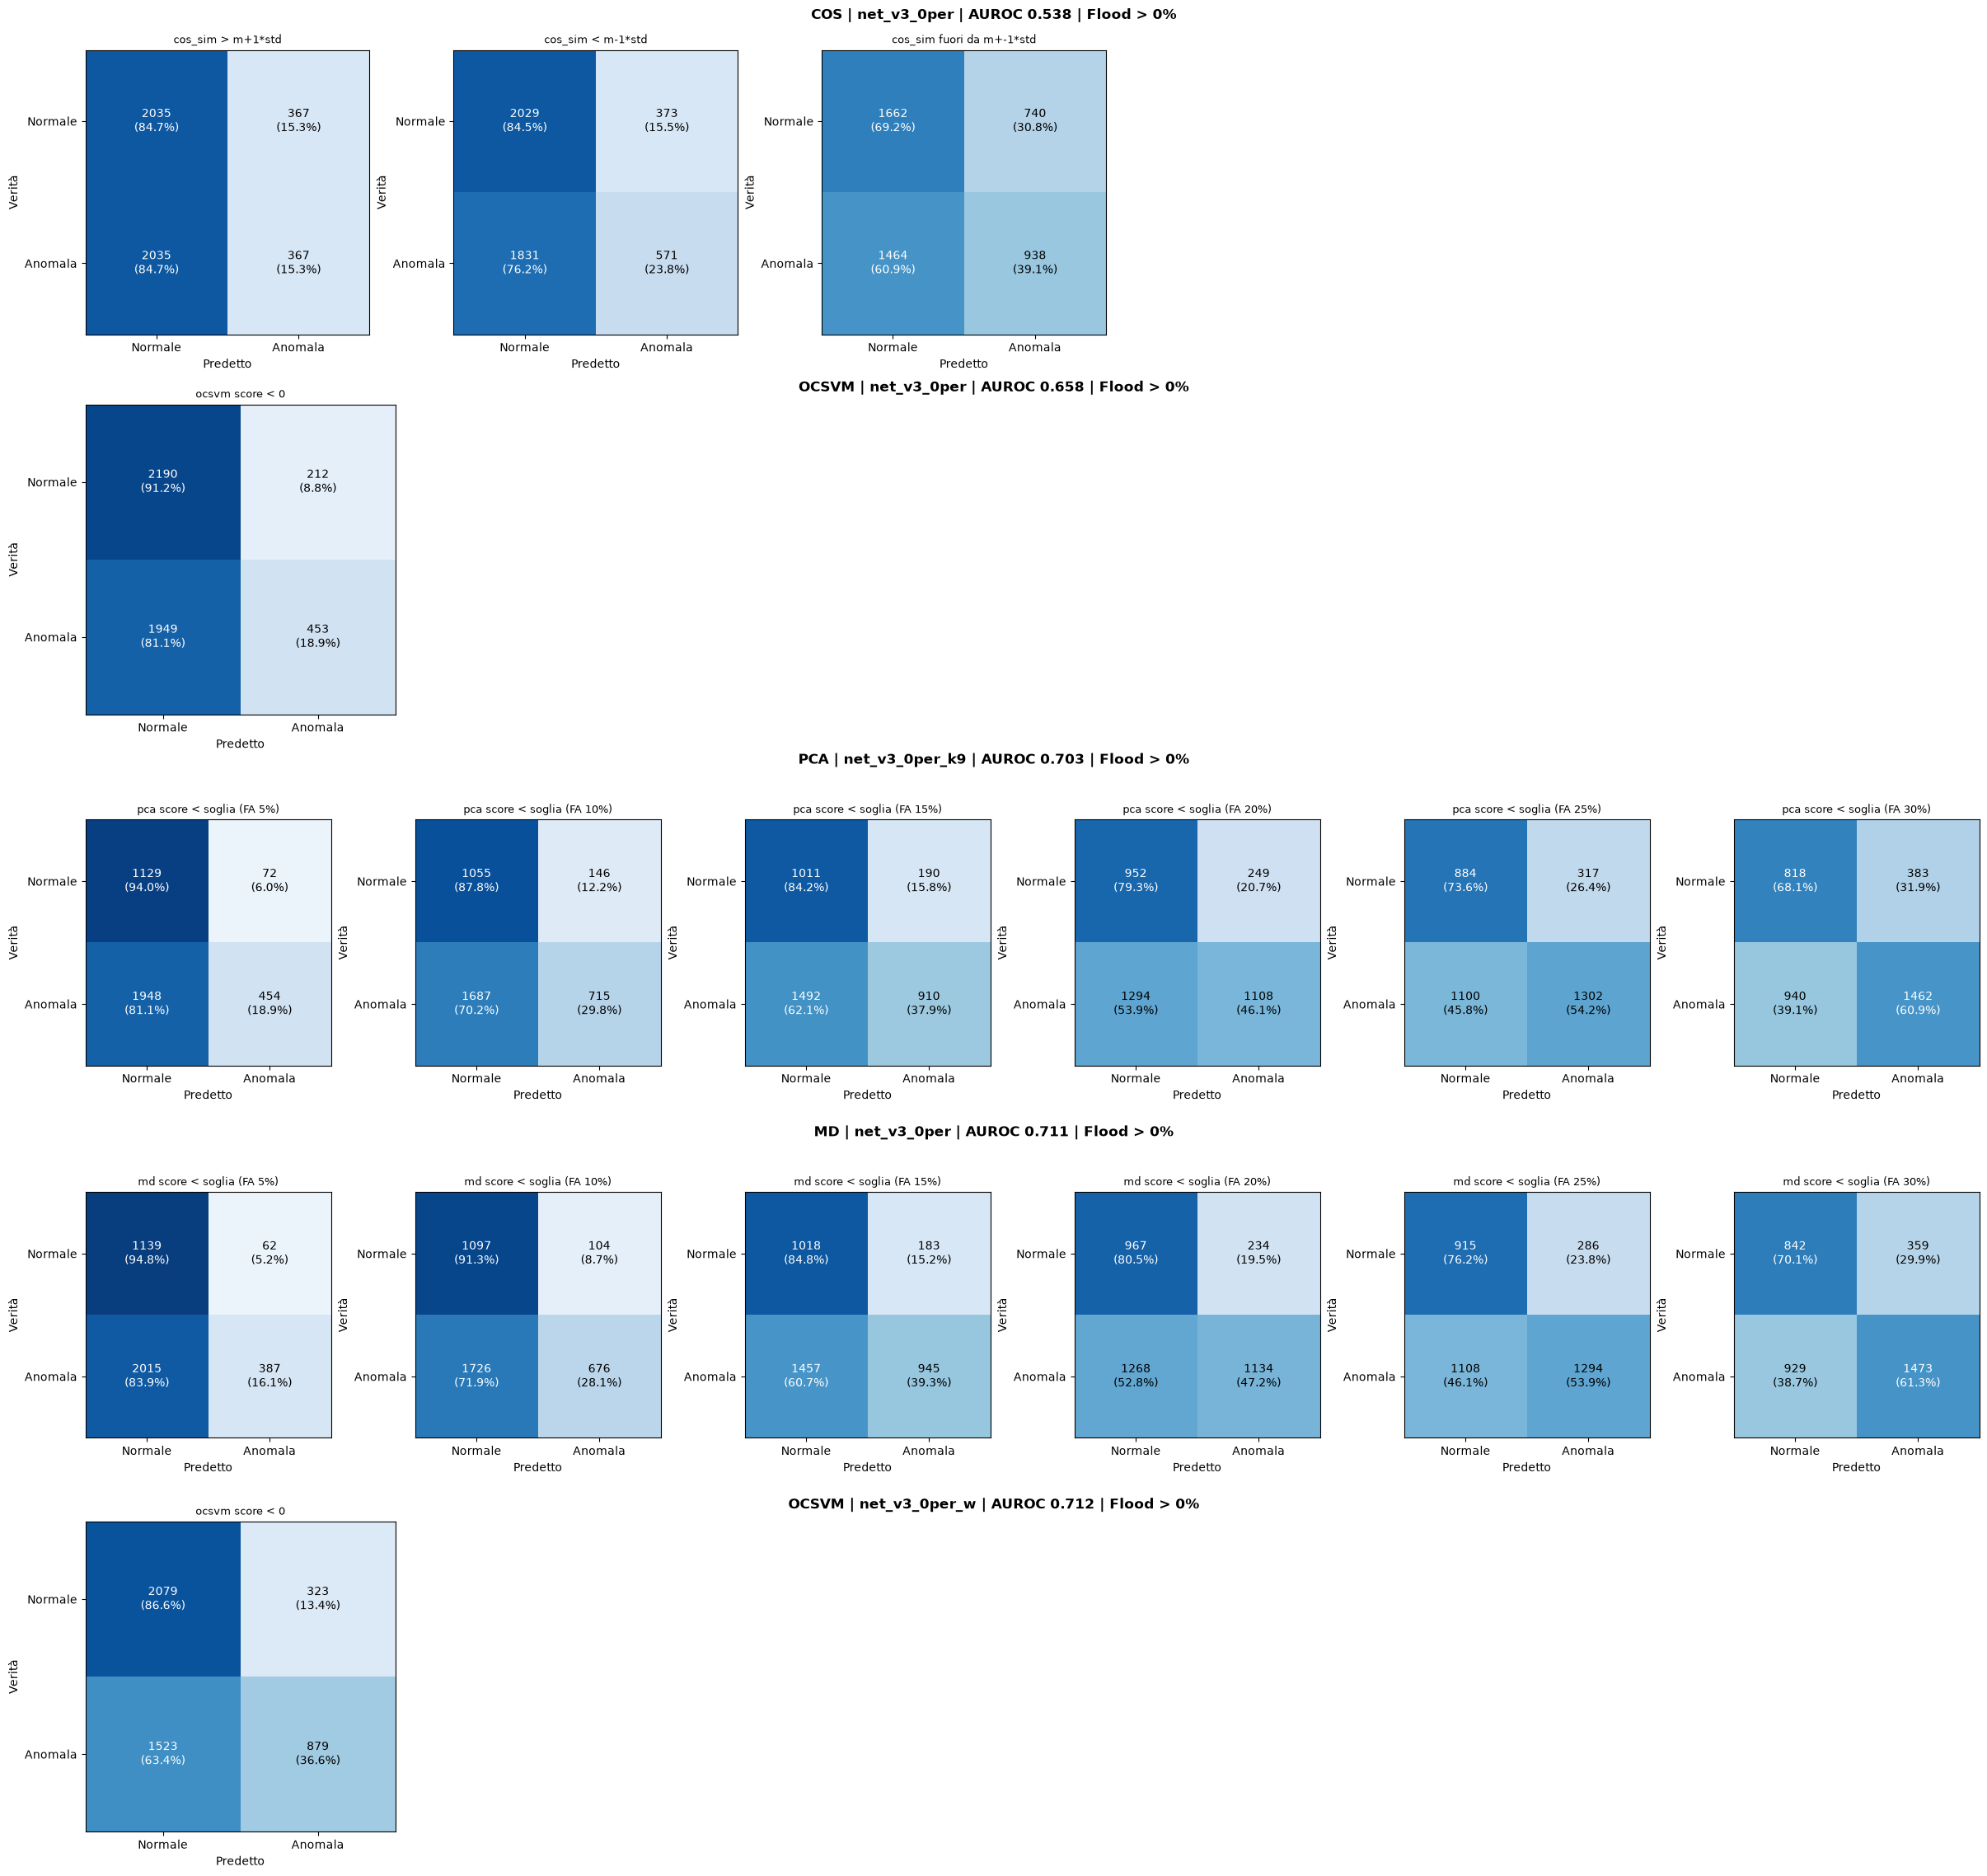

In [51]:
def plot_confusion_row(sfig, metodo, job_name, results, n_cols):
    rules = results["rules"]
    auroc = results.get("auroc", results.get("auroc_cos_sim_low_anom"))
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"{metodo.upper()} | {job_name} | AUROC {auroc:.3f} | Flood > {flood:.0f}%", fontsize=12, fontweight="bold")


loaded = [(metodo, job_name, load_job(metodo, job_name)[0]) for metodo, job_name in jobs]
n_rows = len(loaded)
n_cols = max(len(res["rules"]) for _, _, res in loaded)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * n_rows), layout="constrained")
subfigs = fig.subfigures(n_rows, 1)

for sfig, (metodo, job_name, results) in zip(subfigs, loaded):
    plot_confusion_row(sfig, metodo, job_name, results, n_cols)

plt.show()

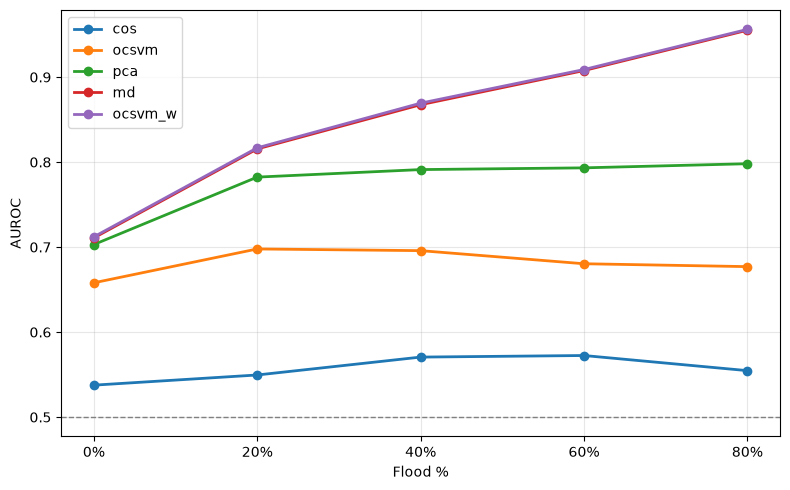

,cos,ocsvm,pca,md,ocsvm_w
min_flood_area,,,,,
0,0.537590,0.658010,0.703005,0.710829,0.712104
20,0.549561,0.697822,0.782344,0.815498,0.816775
40,0.570610,0.695835,0.791197,0.867521,0.869336
60,0.572466,0.680426,0.793236,0.907682,0.908885
80,0.554679,0.677036,0.798089,0.955127,0.956130


In [ ]:
floods = [0, 20, 40, 60, 80]

metodi = [
    ("cos",     "cos",   lambda f: f"net_v3_{f}per"),
    ("ocsvm",   "ocsvm", lambda f: f"net_v3_{f}per"),
    ("pca",     "pca",   lambda f: f"net_v3_{f}per_k9"),
    ("md",      "md",    lambda f: f"net_v3_{f}per"),
    ("ocsvm_w", "ocsvm", lambda f: f"net_v3_{f}per_w"),
]

auroc_table = {}            
for etichetta, metodo, nome in metodi:
    valori = []
    for f in floods:
        try:
            results, _ = load_job(metodo, nome(f))
            valori.append(results.get("auroc", results.get("auroc_cos_sim_low_anom")))
        except Exception as e:
            print(f"EXC -> {metodo}_{nome(f)}: {e}")
            valori.append(np.nan)                                
    auroc_table[etichetta] = valori

df_auroc = pd.DataFrame(auroc_table, index=floods)
df_auroc.index.name = "min_flood_area"

fig, ax = plt.subplots(figsize=(8, 5))
for etichetta in df_auroc.columns:
    ax.plot(df_auroc.index, df_auroc[etichetta], marker="o", linewidth=2, label=etichetta)

ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)         
ax.set_xticks(floods)
ax.set_xticklabels([f"{f}%" for f in floods])
ax.set_xlabel("Flood %")
ax.set_ylabel("AUROC")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

df_auroc